# Feature Engineering & Data Preprocessing for Machine Learning
**AnalystLab Africa – Data analytics Internship** | Dataset: **Loan Prediction Problem**

**Goal:** transform the raw loan application data into a clean, encoded, scaled, machine-learning-ready dataset that can be used to predict whether a loan should be approved (`Loan_Status`).

**Workflow**
1. Setup & data loading
2. Data inspection
3. Data cleaning
4. Feature engineering
5. Outlier detection & treatment
6. Feature encoding
7. Feature scaling
8. Feature selection (correlation + importance)
9. Final ML-ready dataset
10. Applying the same pipeline to the unlabelled test file
11. Answers to the business questions

## 1. Setup & data loading

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression

sns.set_theme(style='whitegrid', context='notebook')
PALETTE = {'Y': '#2a7f62', 'N': '#c4533a'}   # approved / rejected
IMG = '../images/'
RANDOM_STATE = 42

train_raw = pd.read_csv('../data/train.csv')   # labelled (has Loan_Status)
test_raw  = pd.read_csv('../data/test.csv')    # unlabelled (for scoring later)
print('Train:', train_raw.shape, '| Test:', test_raw.shape)

Train: (614, 13) | Test: (367, 12)


## 2. Data inspection
We inspect the **labelled training file** (614 applications). The test file (367 applications) has no target, so it is only used at the end to prove the pipeline generalises.

In [2]:
# First 10 rows
train_raw.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


In [3]:
# Structure: rows/columns, data types, non-null counts
print('Rows, columns:', train_raw.shape)
train_raw.info()

Rows, columns: (614, 13)
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [4]:
# Missing values and duplicates
missing = pd.DataFrame({'missing': train_raw.isna().sum(),
                        'pct': (train_raw.isna().mean()*100).round(2)})
print(missing[missing.missing > 0].sort_values('missing', ascending=False))
print('\nDuplicate rows       :', train_raw.duplicated().sum())
print('Duplicate Loan_IDs   :', train_raw['Loan_ID'].duplicated().sum())

                  missing   pct
Credit_History         50  8.14
Self_Employed          32  5.21
LoanAmount             22  3.58
Dependents             15  2.44
Loan_Amount_Term       14  2.28
Gender                 13  2.12
Married                 3  0.49

Duplicate rows       : 0
Duplicate Loan_IDs   : 0


In [5]:
# Summary statistics (numeric + categorical)
display(train_raw.describe().T.round(2))
display(train_raw.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,614.0,5403.46,6109.04,150.0,2877.5,3812.5,5795.00,81000.0
CoapplicantIncome,614.0,1621.25,2926.25,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,146.41,85.59,9.0,100.0,128.0,168.00,700.0
Loan_Amount_Term,600.0,342.00,65.12,12.0,360.0,360.0,360.00,480.0
Credit_History,564.0,0.84,0.36,0.0,1.0,1.0,1.00,1.0


,count,unique,top,freq
Loan_ID,614,614,LP001002,1
Gender,601,2,Male,489
Married,611,2,Yes,398
Dependents,599,4,0,345
Education,614,2,Graduate,480
Self_Employed,582,2,No,500
Property_Area,614,3,Semiurban,233
Loan_Status,614,2,Y,422


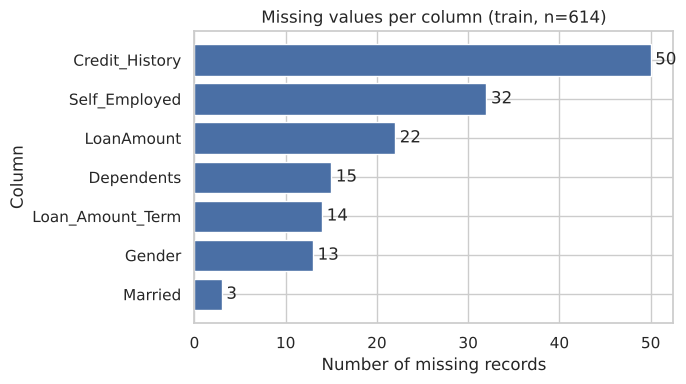

In [6]:
# Visualization 1 - missing values per column
miss = train_raw.isna().sum()
miss = miss[miss > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(miss.index, miss.values, color='#4a6fa5')
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, str(v), va='center')
ax.set_title('Missing values per column (train, n=614)')
ax.set_xlabel('Number of missing records'); ax.set_ylabel('Column')
plt.tight_layout(); plt.savefig(IMG + '01_missing_values.png', dpi=150); plt.show()

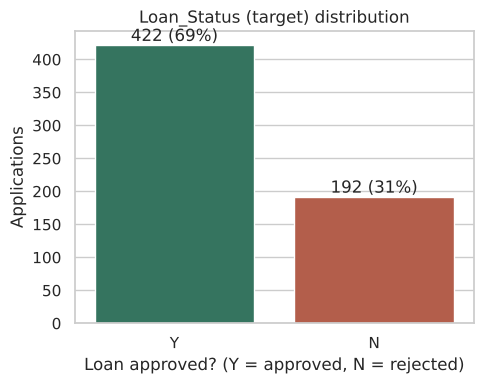

In [7]:
# Visualization 2 - target distribution
fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=train_raw, x='Loan_Status', order=['Y', 'N'], palette=PALETTE, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())} ({p.get_height()/len(train_raw):.0%})',
                (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom')
ax.set_title('Loan_Status (target) distribution')
ax.set_xlabel('Loan approved? (Y = approved, N = rejected)'); ax.set_ylabel('Applications')
plt.tight_layout(); plt.savefig(IMG + '02_target_distribution.png', dpi=150); plt.show()

**Inspection observations**
- 614 rows x 13 columns, no duplicate rows or duplicate Loan_IDs.
- 7 columns contain missing values; `Credit_History` (50) and `Self_Employed` (32) are the worst.
- `Dependents` is stored as text because of the value `3+`; `Credit_History` and `Loan_Amount_Term` are floats that really behave as categories.
- The target is imbalanced (about 69% approved / 31% rejected) - important when choosing evaluation metrics later (F1/ROC-AUC rather than accuracy only).
- Incomes and loan amounts are heavily right-skewed with extreme maxima (income up to 81,000).

## 3. Data cleaning

In [8]:
df = train_raw.copy()

# 3.1 Duplicates (none found, but the check is part of the pipeline)
before = len(df)
df = df.drop_duplicates()
print(f'Duplicates removed: {before - len(df)}')

# 3.2 Rename columns for clarity (snake_case, descriptive)
rename_map = {
    'Loan_ID': 'loan_id', 'Gender': 'gender', 'Married': 'married', 'Dependents': 'dependents',
    'Education': 'education', 'Self_Employed': 'self_employed',
    'ApplicantIncome': 'applicant_income', 'CoapplicantIncome': 'coapplicant_income',
    'LoanAmount': 'loan_amount_k', 'Loan_Amount_Term': 'loan_term_months',
    'Credit_History': 'credit_history', 'Property_Area': 'property_area', 'Loan_Status': 'loan_status'}
df = df.rename(columns=rename_map)
print(list(df.columns))

Duplicates removed: 0
['loan_id', 'gender', 'married', 'dependents', 'education', 'self_employed', 'applicant_income', 'coapplicant_income', 'loan_amount_k', 'loan_term_months', 'credit_history', 'property_area', 'loan_status']


In [9]:
# 3.3 Correct data types
# 'dependents' has the value '3+' -> map to the number 3 (treat as "3 or more")
df['dependents'] = df['dependents'].replace('3+', '3')

# Missing-value FLAGS: record WHERE data was missing before imputing.
# Missing credit history may itself be informative (applicant with no credit record).
df['credit_history_missing'] = df['credit_history'].isna().astype(int)
df['loan_amount_missing']    = df['loan_amount_k'].isna().astype(int)

# 3.4 Missing value handling
# - Categorical / binary columns  -> MODE (most frequent value)
# - credit_history (binary 0/1)   -> MODE (1.0); flag column preserves the information
# - loan_term_months              -> MODE (360 = standard 30-year term; 85% of rows)
# - loan_amount_k (skewed)        -> MEDIAN (robust to the extreme loan amounts)
impute_stats = {}
for c in ['gender', 'married', 'dependents', 'self_employed', 'credit_history', 'loan_term_months']:
    impute_stats[c] = df[c].mode()[0]
impute_stats['loan_amount_k'] = df['loan_amount_k'].median()
print('Imputation values learned from train:', impute_stats)

for c, v in impute_stats.items():
    df[c] = df[c].fillna(v)

df['dependents'] = df['dependents'].astype(int)
df['credit_history'] = df['credit_history'].astype(int)
df['loan_term_months'] = df['loan_term_months'].astype(int)
df['coapplicant_income'] = df['coapplicant_income'].astype(float)
print('\nMissing values after cleaning:', int(df.drop(columns='loan_id').isna().sum().sum()))
df.dtypes

Imputation values learned from train: {'gender': 'Male', 'married': 'Yes', 'dependents': '0', 'self_employed': 'No', 'credit_history': np.float64(1.0), 'loan_term_months': np.float64(360.0), 'loan_amount_k': np.float64(128.0)}

Missing values after cleaning: 0


loan_id                       str
gender                        str
married                       str
dependents                  int64
education                     str
self_employed                 str
applicant_income            int64
coapplicant_income        float64
loan_amount_k             float64
loan_term_months            int64
credit_history              int64
property_area                 str
loan_status                   str
credit_history_missing      int64
loan_amount_missing         int64
dtype: object

**Why these choices?** Mode imputation keeps categorical distributions intact; the median is used for `loan_amount_k` because the mean (146) is pulled up by a few very large loans. Rows were *not* dropped: with only 614 records, dropping the ~22% of rows that have at least one missing value would waste data. The two `_missing` flag columns let a model learn if "missing" itself is a signal.

## 4. Feature engineering
New features are built from business logic used in real credit assessment: *can the household afford the instalment?*

In [10]:
fe = df.copy()

# Total household income (applicant + co-applicant)
fe['total_income'] = fe['applicant_income'] + fe['coapplicant_income']

# Has a co-applicant with income?
fe['has_coapplicant'] = (fe['coapplicant_income'] > 0).astype(int)

# Loan amount is in thousands -> approximate monthly instalment (interest ignored)
fe['emi'] = (fe['loan_amount_k'] * 1000) / fe['loan_term_months']

# Affordability: instalment as a share of monthly household income
fe['emi_to_income'] = fe['emi'] / fe['total_income']

# Loan size relative to income
fe['loan_to_income'] = (fe['loan_amount_k'] * 1000) / fe['total_income']

# Remove irrelevant identifier (unique per row, carries no predictive information)
fe = fe.drop(columns=['loan_id'])

fe[['applicant_income', 'coapplicant_income', 'total_income', 'has_coapplicant',
    'emi', 'emi_to_income', 'loan_to_income']].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
applicant_income,614.0,5403.459,6109.042,150.000,2877.500,3812.500,5795.000,81000.000
coapplicant_income,614.0,1621.246,2926.248,0.000,0.000,1188.500,2297.250,41667.000
total_income,614.0,7024.705,6458.664,1442.000,4166.000,5416.500,7521.750,81000.000
has_coapplicant,614.0,0.555,0.497,0.000,0.000,1.000,1.000,1.000
emi,614.0,473.687,511.134,25.000,288.889,361.111,505.556,9250.000
emi_to_income,614.0,0.077,0.079,0.007,0.055,0.069,0.082,1.237
loan_to_income,614.0,23.877,8.707,2.523,19.221,24.129,28.158,82.712


In [11]:
# Save the CLEANED dataset (readable, unscaled, unencoded + engineered features)
cleaned = fe.copy()
cleaned.to_csv('../data/loan_cleaned.csv', index=False)
print('Saved cleaned dataset:', cleaned.shape)

Saved cleaned dataset: (614, 19)


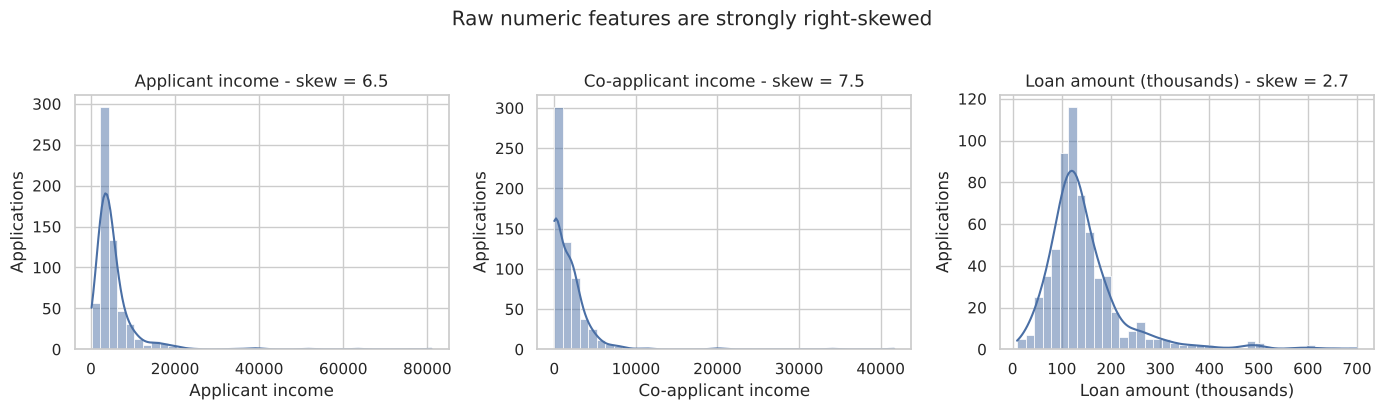

In [12]:
# Visualization 3 - income distributions (raw, skewed)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col, title in zip(axes, ['applicant_income', 'coapplicant_income', 'loan_amount_k'],
                          ['Applicant income', 'Co-applicant income', 'Loan amount (thousands)']):
    sns.histplot(fe[col], bins=40, kde=True, color='#4a6fa5', ax=ax)
    ax.set_title(f'{title} - skew = {fe[col].skew():.1f}')
    ax.set_xlabel(title); ax.set_ylabel('Applications')
plt.suptitle('Raw numeric features are strongly right-skewed', y=1.02)
plt.tight_layout(); plt.savefig(IMG + '03_histograms_raw.png', dpi=150, bbox_inches='tight'); plt.show()

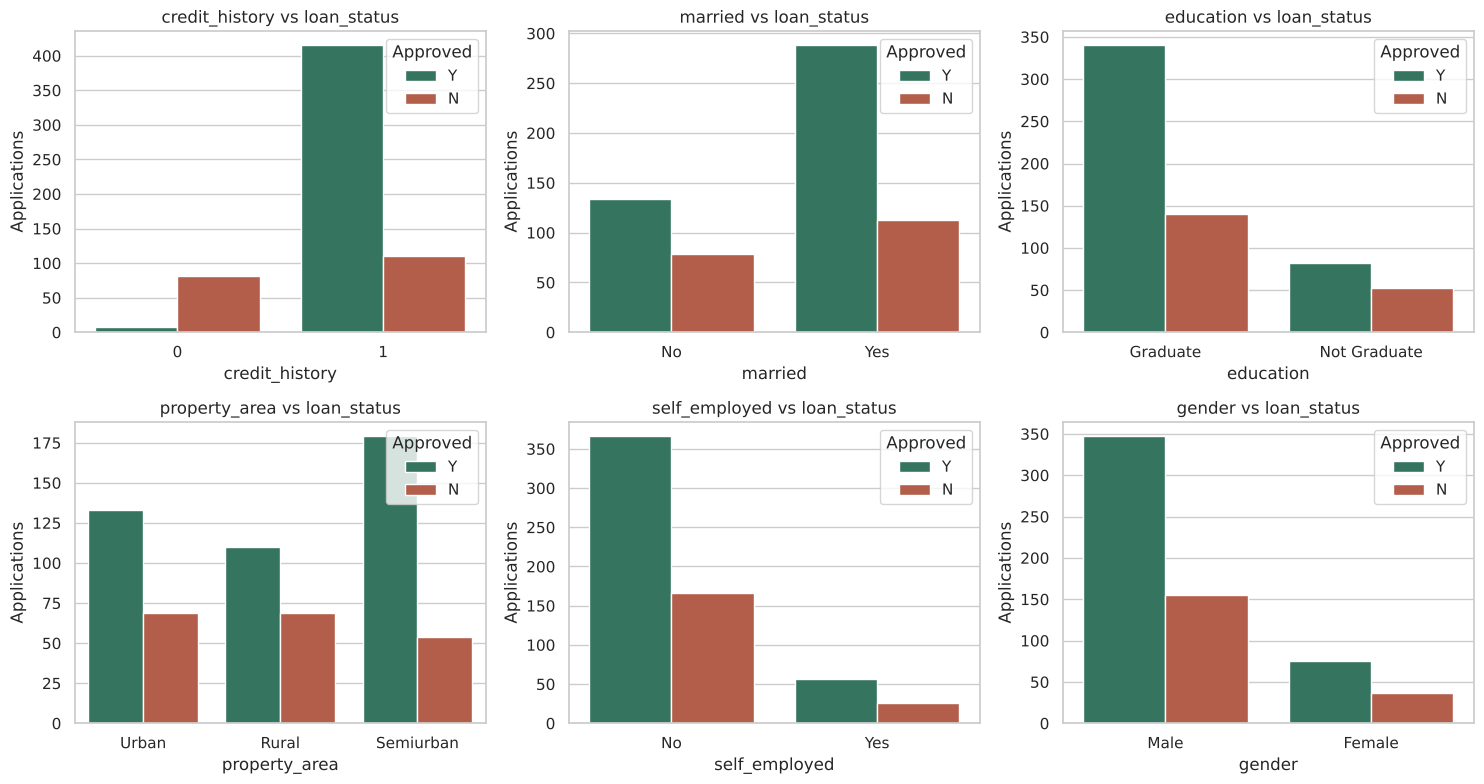

credit_history
0     7.9
1    79.0
Name: approval rate %, dtype: float64


In [13]:
# Visualization 4 - categorical features vs. approval rate
cat_cols = ['credit_history', 'married', 'education', 'property_area', 'self_employed', 'gender']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=fe, x=col, hue='loan_status', hue_order=['Y', 'N'], palette=PALETTE, ax=ax)
    ax.set_title(f'{col} vs loan_status'); ax.set_xlabel(col); ax.set_ylabel('Applications')
    ax.legend(title='Approved', loc='upper right')
plt.tight_layout(); plt.savefig(IMG + '04_countplots_vs_target.png', dpi=150); plt.show()

# Approval rate by credit history - the standout relationship
print((fe.assign(app=(fe.loan_status == 'Y')).groupby('credit_history')['app'].mean()*100).round(1).rename('approval rate %'))

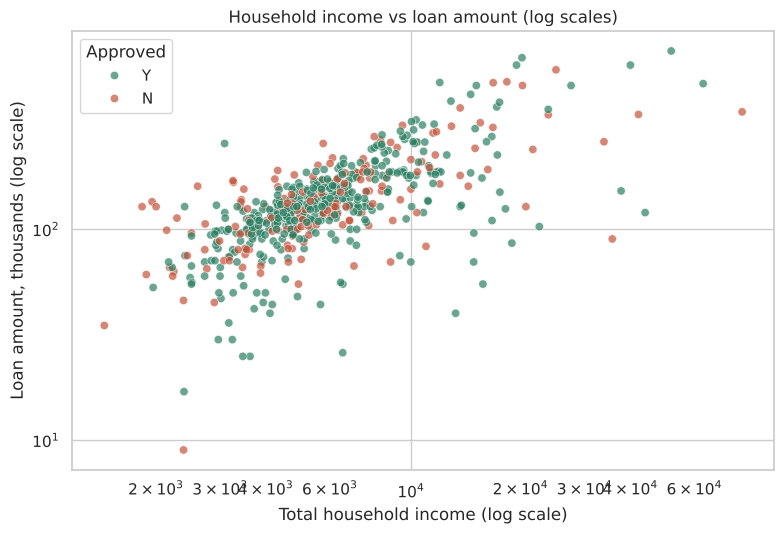

In [14]:
# Visualization 5 - scatter: income vs loan amount, coloured by outcome
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=fe, x='total_income', y='loan_amount_k', hue='loan_status',
                hue_order=['Y', 'N'], palette=PALETTE, alpha=0.7, ax=ax)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Household income vs loan amount (log scales)')
ax.set_xlabel('Total household income (log scale)'); ax.set_ylabel('Loan amount, thousands (log scale)')
ax.legend(title='Approved')
plt.tight_layout(); plt.savefig(IMG + '05_scatter_income_loan.png', dpi=150); plt.show()

## 5. Outlier detection & treatment
**Detection:** boxplots + IQR rule (value < Q1 - 1.5*IQR or > Q3 + 1.5*IQR) and Z-scores.
**Treatment decision:** the extreme values (e.g. income of 81,000) are plausible real applicants, not data-entry errors, so deleting them would discard genuine high-income customers and bias the model. Instead we (1) apply a `log1p` transform to compress the skew, then (2) **cap (winsorise) at the IQR bounds** so no single record dominates scaling or linear-model coefficients. No rows are lost.

In [15]:
num_cols = ['applicant_income', 'coapplicant_income', 'total_income', 'loan_amount_k',
            'emi', 'emi_to_income', 'loan_to_income']

def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k*iqr, q3 + k*iqr

rows = []
for c in num_cols:
    lo, hi = iqr_bounds(fe[c])
    z = (fe[c] - fe[c].mean()) / fe[c].std()
    rows.append({'feature': c, 'IQR_lower': round(lo, 2), 'IQR_upper': round(hi, 2),
                 'IQR_outliers': int(((fe[c] < lo) | (fe[c] > hi)).sum()),
                 'abs_Z>3': int((z.abs() > 3).sum()), 'skew': round(fe[c].skew(), 2)})
pd.DataFrame(rows)

,feature,IQR_lower,IQR_upper,IQR_outliers,abs_Z>3,skew
0,applicant_income,-1498.75,10171.25,50,8,6.54
1,coapplicant_income,-3445.88,5743.12,18,6,7.49
2,total_income,-867.62,12555.38,50,10,5.63
3,loan_amount_k,3.50,261.50,41,15,2.74
4,emi,-36.11,830.56,50,9,9.96
5,emi_to_income,0.02,0.12,51,4,11.26
6,loan_to_income,5.81,41.56,25,8,1.18


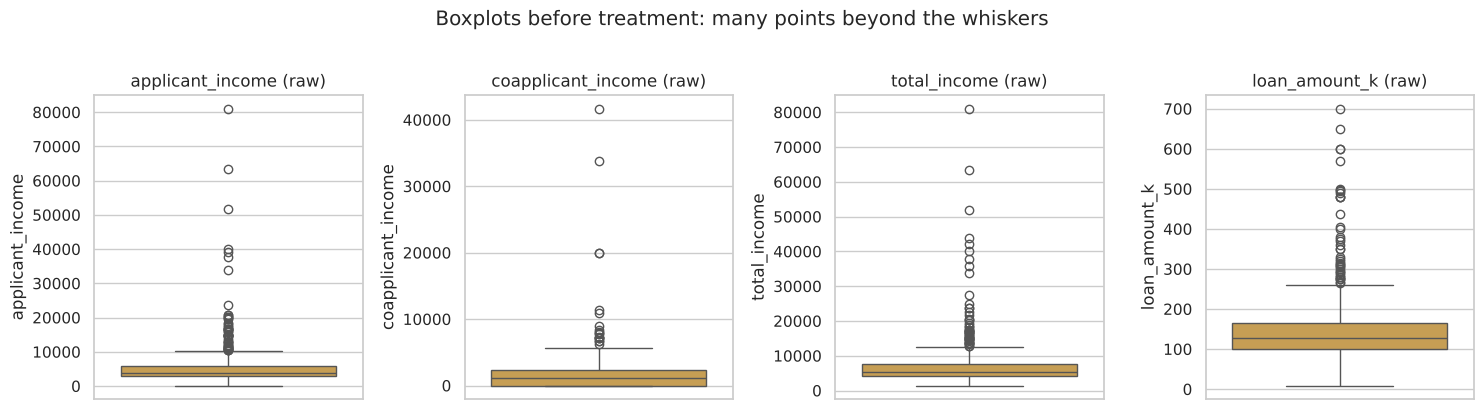

In [16]:
# Visualization 6 - boxplots BEFORE treatment
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, c in zip(axes, ['applicant_income', 'coapplicant_income', 'total_income', 'loan_amount_k']):
    sns.boxplot(y=fe[c], color='#d9a441', ax=ax)
    ax.set_title(f'{c} (raw)'); ax.set_ylabel(c)
plt.suptitle('Boxplots before treatment: many points beyond the whiskers', y=1.02)
plt.tight_layout(); plt.savefig(IMG + '06_boxplots_before.png', dpi=150, bbox_inches='tight'); plt.show()

In [17]:
# Treatment: log1p transform, then IQR capping (bounds learned on TRAIN only)
skewed = ['applicant_income', 'coapplicant_income', 'total_income', 'loan_amount_k',
          'emi', 'emi_to_income', 'loan_to_income']
caps = {}
tx = fe.copy()
for c in skewed:
    tx[c + '_log'] = np.log1p(tx[c])
    lo, hi = iqr_bounds(tx[c + '_log'])
    caps[c + '_log'] = (lo, hi)
    n_cap = int(((tx[c + '_log'] < lo) | (tx[c + '_log'] > hi)).sum())
    tx[c + '_log'] = tx[c + '_log'].clip(lo, hi)
    print(f'{c + "_log":28s} capped values: {n_cap:3d}  | skew {fe[c].skew():6.2f} -> {tx[c + "_log"].skew():5.2f}')

applicant_income_log         capped values:  27  | skew   6.54 ->  0.52
coapplicant_income_log       capped values:   0  | skew   7.49 -> -0.17
total_income_log             capped values:  22  | skew   5.63 ->  0.48
loan_amount_k_log            capped values:  39  | skew   2.74 ->  0.04
emi_log                      capped values:  34  | skew   9.96 ->  0.28
emi_to_income_log            capped values:  48  | skew  11.26 ->  0.24
loan_to_income_log           capped values:  46  | skew   1.18 -> -0.54


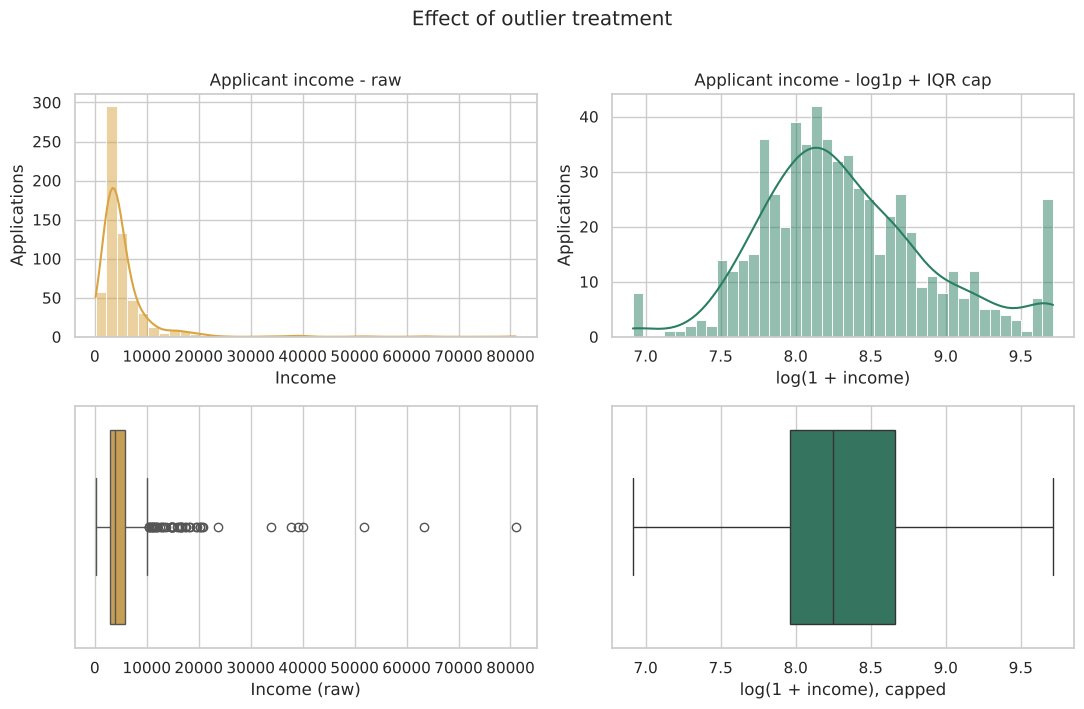

In [18]:
# Visualization 7 - before vs after (applicant income)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
sns.histplot(fe['applicant_income'], bins=40, kde=True, color='#d9a441', ax=axes[0, 0])
axes[0, 0].set_title('Applicant income - raw'); axes[0, 0].set_xlabel('Income')
sns.histplot(tx['applicant_income_log'], bins=40, kde=True, color='#2a7f62', ax=axes[0, 1])
axes[0, 1].set_title('Applicant income - log1p + IQR cap'); axes[0, 1].set_xlabel('log(1 + income)')
sns.boxplot(x=fe['applicant_income'], color='#d9a441', ax=axes[1, 0]); axes[1, 0].set_xlabel('Income (raw)')
sns.boxplot(x=tx['applicant_income_log'], color='#2a7f62', ax=axes[1, 1]); axes[1, 1].set_xlabel('log(1 + income), capped')
for ax in axes[0]: ax.set_ylabel('Applications')
plt.suptitle('Effect of outlier treatment', y=1.01)
plt.tight_layout(); plt.savefig(IMG + '07_outlier_treatment.png', dpi=150, bbox_inches='tight'); plt.show()

## 6. Feature encoding
| Column | Type | Technique | Why |
|---|---|---|---|
| `loan_status` (target) | binary | Label encode Y=1, N=0 | Models need numeric target; 1 = approved |
| `gender`, `married`, `education`, `self_employed` | binary nominal | Label / binary encode (0/1) | Only 2 categories -> a single 0/1 column is enough, no extra dimensions |
| `property_area` | nominal, 3 levels | **One-hot** (drop first) | No natural order (Rural < Urban would be a false assumption); drop-first avoids the dummy-variable trap |
| `dependents` | ordinal | Kept as integer 0-3 | Order is meaningful (more dependents = more obligations) |
| `credit_history`, `has_coapplicant` | already 0/1 | none | Already binary |

In [19]:
enc = tx.copy()

# Label / binary encoding (explicit mappings so the meaning of 0/1 is documented)
enc['loan_status']   = enc['loan_status'].map({'Y': 1, 'N': 0})
enc['gender']        = enc['gender'].map({'Male': 1, 'Female': 0})
enc['married']       = enc['married'].map({'Yes': 1, 'No': 0})
enc['education']     = enc['education'].map({'Graduate': 1, 'Not Graduate': 0})
enc['self_employed'] = enc['self_employed'].map({'Yes': 1, 'No': 0})

# One-hot encoding for the nominal 3-level column
AREA_LEVELS = ['Rural', 'Semiurban', 'Urban']
enc = pd.get_dummies(enc, columns=['property_area'], prefix='area', drop_first=True, dtype=int)
print('Encoded columns:', [c for c in enc.columns if c.startswith('area_')])
print('Remaining object columns:', list(enc.select_dtypes('object').columns))
enc.head()

Encoded columns: ['area_Semiurban', 'area_Urban']
Remaining object columns: []


,gender,married,dependents,education,self_employed,applicant_income,coapplicant_income,loan_amount_k,loan_term_months,credit_history,...,loan_to_income,applicant_income_log,coapplicant_income_log,total_income_log,loan_amount_k_log,emi_log,emi_to_income_log,loan_to_income_log,area_Semiurban,area_Urban
0,1,0,0,1,0,5849,0.0,128.0,360,1,...,21.884083,8.674197,0.000000,8.674197,4.859812,5.876490,0.059013,3.130442,0,1
1,1,1,1,1,0,4583,1508.0,128.0,360,1,...,21.014612,8.430327,7.319202,8.714732,4.859812,5.876490,0.056734,3.091706,0,0
2,1,1,0,1,1,3000,0.0,66.0,360,1,...,22.000000,8.006701,0.000000,8.006701,4.204693,5.216746,0.059317,3.135494,0,1
3,1,1,0,0,0,2583,2358.0,120.0,360,1,...,24.286582,7.857094,7.765993,8.505525,4.795791,5.812138,0.065285,3.230274,0,1
4,1,0,0,1,0,6000,0.0,141.0,360,1,...,23.500000,8.699681,0.000000,8.699681,4.955827,5.972961,0.063236,3.198673,0,1


## 7. Feature scaling
**Choice: `StandardScaler`** (zero mean, unit variance) applied only to continuous features, *after* log transform + capping.
- Outliers have already been tamed, so the main weakness of StandardScaler (sensitivity to outliers) is addressed; `RobustScaler` would be the alternative if we had kept the raw extremes.
- Distance- and gradient-based models (Logistic Regression, KNN, SVM, neural nets) need features on comparable scales; tree models are unaffected but not harmed.
- `MinMaxScaler` was rejected because it is compressed by any remaining extreme value and gives no benefit here.
- Binary/one-hot columns are **not** scaled (already 0/1).

In [20]:
cont_cols = ['applicant_income_log', 'coapplicant_income_log', 'total_income_log', 'loan_amount_k_log',
             'emi_log', 'emi_to_income_log', 'loan_to_income_log', 'loan_term_months', 'dependents']

scaler = StandardScaler()
scaled = enc.copy()
scaled[cont_cols] = scaler.fit_transform(enc[cont_cols])

print('Mean (should be ~0) :', scaled[cont_cols].mean().round(3).to_dict())
print('Std  (should be ~1) :', scaled[cont_cols].std().round(3).to_dict())

Mean (should be ~0) : {'applicant_income_log': 0.0, 'coapplicant_income_log': -0.0, 'total_income_log': 0.0, 'loan_amount_k_log': 0.0, 'emi_log': -0.0, 'emi_to_income_log': 0.0, 'loan_to_income_log': 0.0, 'loan_term_months': 0.0, 'dependents': 0.0}
Std  (should be ~1) : {'applicant_income_log': 1.001, 'coapplicant_income_log': 1.001, 'total_income_log': 1.001, 'loan_amount_k_log': 1.001, 'emi_log': 1.001, 'emi_to_income_log': 1.001, 'loan_to_income_log': 1.001, 'loan_term_months': 1.001, 'dependents': 1.001}


## 8. Feature selection
We combine three views: (1) correlation heatmap to find redundant features, (2) Random Forest importance, (3) mutual information with the target.

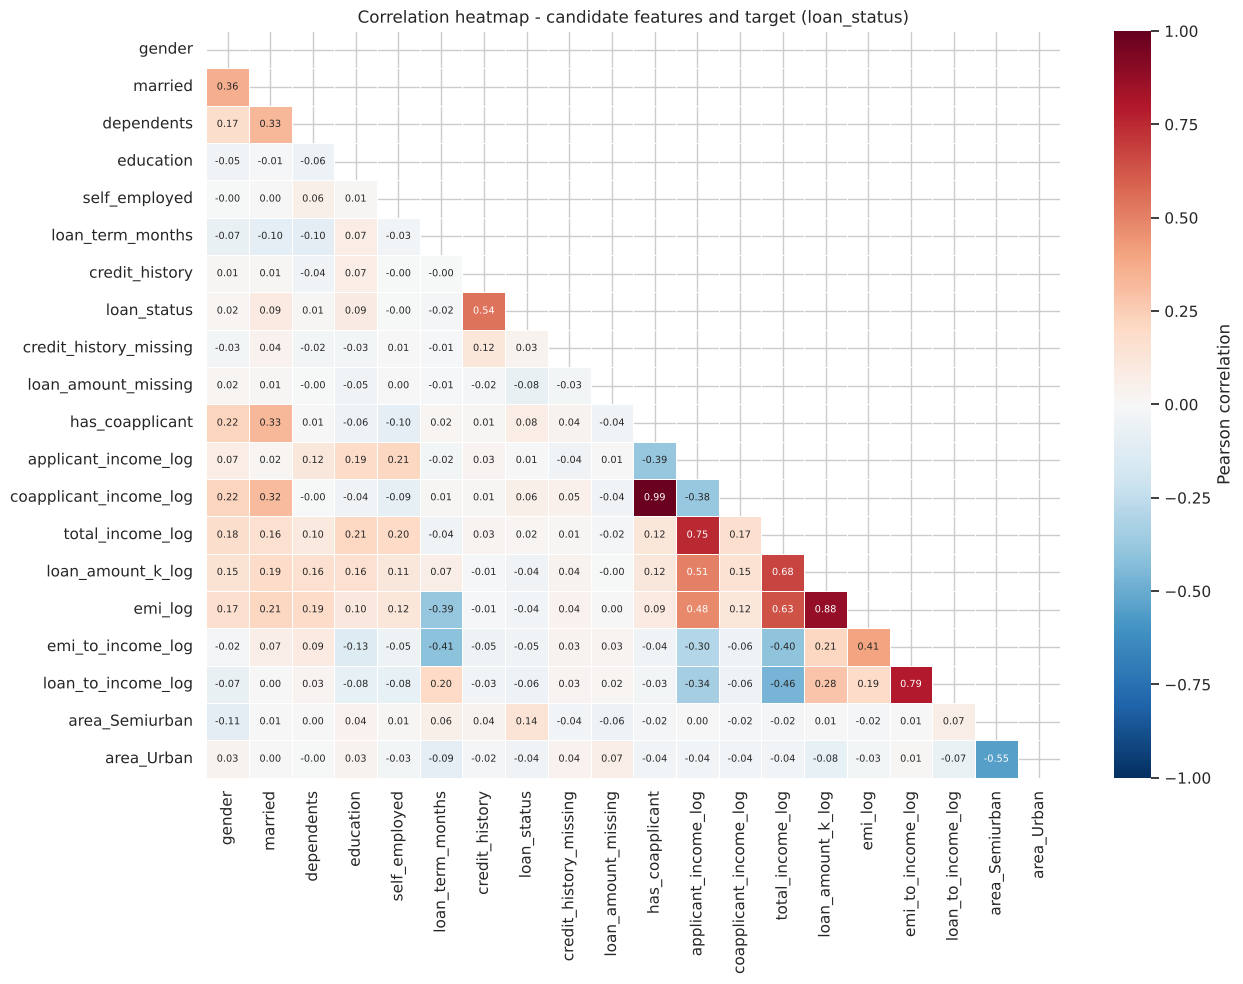

Correlation with target (loan_status):
credit_history            0.541
area_Semiurban            0.137
married                   0.091
education                 0.086
loan_amount_missing      -0.078
has_coapplicant           0.075
coapplicant_income_log    0.061
loan_to_income_log       -0.056
emi_to_income_log        -0.047
loan_amount_k_log        -0.045
area_Urban               -0.044
emi_log                  -0.038
credit_history_missing    0.034
loan_term_months         -0.023
gender                    0.018
total_income_log          0.017
dependents                0.010
applicant_income_log      0.006
self_employed            -0.004
Name: loan_status, dtype: float64


In [21]:
# Drop raw (un-logged, un-capped) columns - they were replaced by their *_log versions
raw_replaced = ['applicant_income', 'coapplicant_income', 'total_income', 'loan_amount_k',
                'emi', 'emi_to_income', 'loan_to_income']
cand = scaled.drop(columns=raw_replaced)
X_cand = cand.drop(columns='loan_status'); y = cand['loan_status']

# Visualization 8 - correlation heatmap (all candidate features + target)
corr = cand.corr()
fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            linewidths=0.4, annot_kws={'size': 7}, cbar_kws={'label': 'Pearson correlation'}, ax=ax)
ax.set_title('Correlation heatmap - candidate features and target (loan_status)')
plt.tight_layout(); plt.savefig(IMG + '08_correlation_heatmap.png', dpi=150); plt.show()

print('Correlation with target (loan_status):')
print(corr['loan_status'].drop('loan_status').sort_values(key=abs, ascending=False).round(3))

In [22]:
# Highly correlated feature pairs (|r| > 0.80)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().reset_index())
pairs.columns = ['feature_a', 'feature_b', 'r']
high = pairs[pairs['r'].abs() > 0.80].sort_values('r', key=abs, ascending=False)
print('Pairs with |r| > 0.80:'); display(high)

Pairs with |r| > 0.80:


,feature_a,feature_b,r
212,has_coapplicant,coapplicant_income_log,0.991194
295,loan_amount_k_log,emi_log,0.880133


,feature,rf_importance,mutual_info
0,credit_history,0.2869,0.1322
1,loan_to_income_log,0.1024,0.0000
2,emi_to_income_log,0.0933,0.0000
3,total_income_log,0.0916,0.0000
4,applicant_income_log,0.0901,0.0019
5,emi_log,0.0741,0.0000
6,loan_amount_k_log,0.0710,0.0000
7,coapplicant_income_log,0.0534,0.0198
8,area_Semiurban,0.0262,0.0477
9,dependents,0.0227,0.0264


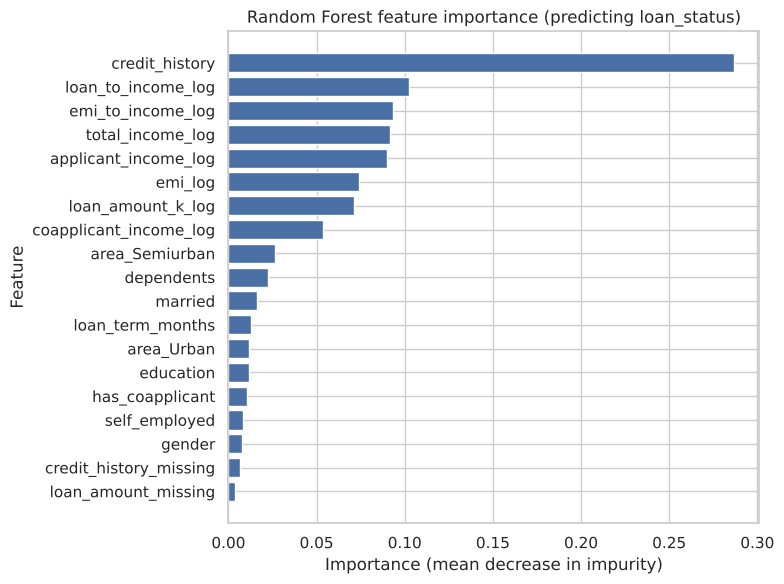

In [23]:
# Random Forest importance + mutual information
rf = RandomForestClassifier(n_estimators=500, random_state=RANDOM_STATE, class_weight='balanced',
                            min_samples_leaf=3, n_jobs=-1).fit(X_cand, y)
imp = pd.DataFrame({
    'feature': X_cand.columns,
    'rf_importance': rf.feature_importances_,
    'mutual_info': mutual_info_classif(X_cand, y, random_state=RANDOM_STATE, discrete_features=False)
}).sort_values('rf_importance', ascending=False).reset_index(drop=True)
display(imp.round(4))

# Visualization 9 - feature importance
fig, ax = plt.subplots(figsize=(8, 6))
d = imp.sort_values('rf_importance')
ax.barh(d['feature'], d['rf_importance'], color='#4a6fa5')
ax.set_title('Random Forest feature importance (predicting loan_status)')
ax.set_xlabel('Importance (mean decrease in impurity)'); ax.set_ylabel('Feature')
plt.tight_layout(); plt.savefig(IMG + '09_feature_importance.png', dpi=150); plt.show()

In [24]:
# Selection rule:
#  1) For every pair with |r| > 0.80 drop the member with the LOWER random-forest importance.
#  2) Drop features with near-zero importance AND near-zero mutual information AND |corr with target| < 0.02
#     (checked below, flagged but only dropped if all three agree).
rf_imp = imp.set_index('feature')['rf_importance']
drop_redundant = set()
for _, r in high.iterrows():
    a, b = r['feature_a'], r['feature_b']
    if a in drop_redundant or b in drop_redundant:
        continue
    drop_redundant.add(a if rf_imp[a] < rf_imp[b] else b)
print('Dropped as redundant (high correlation):', sorted(drop_redundant))

tgt_corr = corr['loan_status'].drop('loan_status').abs()
weak = [f for f in X_cand.columns
        if f not in drop_redundant
        and rf_imp[f] < rf_imp.quantile(0.10)
        and imp.set_index('feature').loc[f, 'mutual_info'] < 0.005
        and tgt_corr[f] < 0.02]
print('Dropped as uninformative (all three criteria agree):', weak)

selected = [f for f in X_cand.columns if f not in drop_redundant and f not in weak]
print('\nSelected features (%d):' % len(selected)); print(selected)

Dropped as redundant (high correlation): ['has_coapplicant', 'loan_amount_k_log']
Dropped as uninformative (all three criteria agree): []

Selected features (17):
['gender', 'married', 'dependents', 'education', 'self_employed', 'loan_term_months', 'credit_history', 'credit_history_missing', 'loan_amount_missing', 'applicant_income_log', 'coapplicant_income_log', 'total_income_log', 'emi_log', 'emi_to_income_log', 'loan_to_income_log', 'area_Semiurban', 'area_Urban']


In [25]:
# Sanity check: does selection hurt? 5-fold CV ROC-AUC before vs after (Logistic Regression)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
lr = LogisticRegression(max_iter=1000, class_weight='balanced')
auc_all = cross_val_score(lr, X_cand, y, cv=cv, scoring='roc_auc').mean()
auc_sel = cross_val_score(lr, X_cand[selected], y, cv=cv, scoring='roc_auc').mean()
print(f'ROC-AUC all candidate features ({X_cand.shape[1]}): {auc_all:.3f}')
print(f'ROC-AUC selected features      ({len(selected)}): {auc_sel:.3f}')

ROC-AUC all candidate features (19): 0.747
ROC-AUC selected features      (17): 0.746


## 9. Final machine-learning-ready dataset

In [26]:
ml_ready = cand[selected + ['loan_status']].copy()

# Final quality gates
assert ml_ready.isna().sum().sum() == 0, 'NaNs remain'
assert all(pd.api.types.is_numeric_dtype(t) for t in ml_ready.dtypes), 'Non-numeric column remains'

ml_ready.to_csv('../data/loan_ml_ready.csv', index=False)
print('Saved ML-ready dataset:', ml_ready.shape)
print('Target balance:', ml_ready['loan_status'].value_counts(normalize=True).round(3).to_dict())
display(ml_ready.head(10).round(3))
display(ml_ready.dtypes.to_frame('dtype').T)

Saved ML-ready dataset: (614, 18)
Target balance: {1: 0.687, 0: 0.313}


,gender,married,dependents,education,self_employed,loan_term_months,credit_history,credit_history_missing,loan_amount_missing,applicant_income_log,coapplicant_income_log,total_income_log,emi_log,emi_to_income_log,loan_to_income_log,area_Semiurban,area_Urban,loan_status
0,1,0,-0.738,1,0,0.273,1,0,1,0.596,-1.108,0.043,-0.154,-0.376,-0.121,0,1,1
1,1,1,0.253,1,0,0.273,1,0,0,0.167,0.782,0.125,-0.154,-0.481,-0.243,0,0,0
2,1,1,-0.738,1,1,0.273,1,0,0,-0.577,-1.108,-1.312,-1.507,-0.363,-0.105,0,1,1
3,1,1,-0.738,0,0,0.273,1,0,0,-0.839,0.898,-0.299,-0.286,-0.089,0.195,0,1,1
4,1,0,-0.738,1,0,0.273,1,0,0,0.641,-1.108,0.095,0.044,-0.183,0.095,0,1,1
5,1,1,1.245,1,1,0.273,1,0,0,0.461,1.046,1.052,1.351,0.326,0.603,0,1,1
6,1,1,-0.738,0,0,0.273,1,0,0,-1.018,0.784,-0.806,-0.763,-0.041,0.244,0,1,1
7,1,1,2.236,1,0,0.273,0,0,0,-0.556,0.913,-0.067,0.277,0.414,0.684,1,0,0
8,1,1,1.245,1,0,0.273,1,0,0,-0.069,0.785,-0.070,0.403,0.632,0.876,0,1,1
9,1,1,0.253,1,0,0.273,1,0,0,1.977,1.294,2.352,1.900,-1.254,-1.320,1,0,0


,gender,married,dependents,education,self_employed,loan_term_months,credit_history,credit_history_missing,loan_amount_missing,applicant_income_log,coapplicant_income_log,total_income_log,emi_log,emi_to_income_log,loan_to_income_log,area_Semiurban,area_Urban,loan_status
dtype,int64,int64,float64,int64,int64,float64,int64,int64,int64,float64,float64,float64,float64,float64,float64,int64,int64,int64


### Preprocessing summary
| Step | What was done | Result |
|---|---|---|
| Duplicates | Checked rows and Loan_ID | none found |
| Missing values | Mode (categorical, credit history, term), median (loan amount) + 2 missing-flag columns | 0 missing |
| Data types | `3+` -> 3, floats -> ints, text -> numeric | all numeric |
| Feature engineering | total income, co-applicant flag, EMI, EMI-to-income, loan-to-income | 5 new features |
| Irrelevant features | `loan_id` dropped | identifier only |
| Outliers | `log1p` + IQR capping, no rows removed | skew greatly reduced |
| Encoding | binary mapping, one-hot for property area, ordinal dependents | numeric |
| Scaling | StandardScaler on continuous columns | mean 0, std 1 |
| Selection | correlation (>0.80) + RF importance + mutual information | 2 redundant features dropped, 17 features kept |

## 10. Applying the same pipeline to the unlabelled test file
To show the pipeline is reusable, every parameter learned on **train** (imputation values, capping bounds, scaler, selected columns) is applied to the test file - nothing is re-fitted on test, which avoids data leakage.

In [27]:
def preprocess_new(raw):
    d = raw.rename(columns=rename_map).copy()
    d['dependents'] = d['dependents'].replace('3+', '3')
    d['credit_history_missing'] = d['credit_history'].isna().astype(int)
    d['loan_amount_missing'] = d['loan_amount_k'].isna().astype(int)
    for c, v in impute_stats.items():
        d[c] = d[c].fillna(v)
    d['dependents'] = d['dependents'].astype(int)
    d['total_income'] = d['applicant_income'] + d['coapplicant_income']
    d['has_coapplicant'] = (d['coapplicant_income'] > 0).astype(int)
    d['emi'] = d['loan_amount_k'] * 1000 / d['loan_term_months']
    d['emi_to_income'] = d['emi'] / d['total_income']
    d['loan_to_income'] = d['loan_amount_k'] * 1000 / d['total_income']
    ids = d['loan_id']
    for c in skewed:
        lo, hi = caps[c + '_log']
        d[c + '_log'] = np.log1p(d[c]).clip(lo, hi)
    d['gender'] = d['gender'].map({'Male': 1, 'Female': 0})
    d['married'] = d['married'].map({'Yes': 1, 'No': 0})
    d['education'] = d['education'].map({'Graduate': 1, 'Not Graduate': 0})
    d['self_employed'] = d['self_employed'].map({'Yes': 1, 'No': 0})
    for lvl in AREA_LEVELS[1:]:
        d['area_' + lvl] = (d['property_area'] == lvl).astype(int)
    d[cont_cols] = scaler.transform(d[cont_cols])
    out = d[selected].copy()
    out.insert(0, 'loan_id', ids.values)
    return out

test_ready = preprocess_new(test_raw)
test_ready.drop(columns='loan_id').isna().sum().sum()
test_ready.to_csv('../data/loan_ml_ready_test.csv', index=False)
print('Test ML-ready shape:', test_ready.shape, '| NaNs:', int(test_ready.drop(columns="loan_id").isna().sum().sum()))
assert list(test_ready.columns[1:]) == selected

# Consistency check: re-processing the TRAIN file with the function must reproduce the ML-ready train data
chk = preprocess_new(train_raw.drop(columns='Loan_Status')).drop(columns='loan_id')
print('Pipeline reproduces train ML-ready features:', np.allclose(chk.values, ml_ready[selected].values))

Test ML-ready shape: (367, 18) | NaNs: 0
Pipeline reproduces train ML-ready features: True


## 11. Answers to the business questions

In [28]:
top = imp.head(5)['feature'].tolist()
print('Q1 Most relevant features (RF importance):', top)
print('   Correlation with approval -> credit_history r = %.2f' % corr.loc['credit_history', 'loan_status'])
print('Q2 Encoding needed: gender, married, education, self_employed (binary), property_area (one-hot), loan_status (target), dependents (ordinal int)')
print('Q3 Scaling needed:', cont_cols)
print('Q4 Redundant/correlated pairs (|r|>0.8):', [(a, b, round(r, 2)) for a, b, r in high.values] or 'none',
      '-> dropped:', sorted(drop_redundant))
print('Q5 Missing values: mode/median + flags; outliers: log1p + IQR capping (no rows removed)')
print('Q7 Ready for ML? Rows =', len(ml_ready), '| NaNs =', int(ml_ready.isna().sum().sum()),
      '| all numeric =', all(pd.api.types.is_numeric_dtype(t) for t in ml_ready.dtypes))

Q1 Most relevant features (RF importance): ['credit_history', 'loan_to_income_log', 'emi_to_income_log', 'total_income_log', 'applicant_income_log']
   Correlation with approval -> credit_history r = 0.54
Q2 Encoding needed: gender, married, education, self_employed (binary), property_area (one-hot), loan_status (target), dependents (ordinal int)
Q3 Scaling needed: ['applicant_income_log', 'coapplicant_income_log', 'total_income_log', 'loan_amount_k_log', 'emi_log', 'emi_to_income_log', 'loan_to_income_log', 'loan_term_months', 'dependents']
Q4 Redundant/correlated pairs (|r|>0.8): [('has_coapplicant', 'coapplicant_income_log', 0.99), ('loan_amount_k_log', 'emi_log', 0.88)] -> dropped: ['has_coapplicant', 'loan_amount_k_log']
Q5 Missing values: mode/median + flags; outliers: log1p + IQR capping (no rows removed)
Q7 Ready for ML? Rows = 614 | NaNs = 0 | all numeric = True


**Answers**
1. **Most relevant features:** `credit_history` dominates on every measure (RF importance 0.29, correlation with approval r = 0.54, mutual information 0.13 - far above anything else). The affordability ratios (`loan_to_income`, `emi_to_income`) and the income features come next in RF importance (about 0.09-0.10 each), but note that RF importance is biased towards continuous features and their correlation with the target is weak (|r| < 0.06). Among categorical features `property_area` (Semiurban, r = 0.14), `married` and `education` carry the most signal; `gender` and `self_employed` are weak.
2. **Encoding required:** four binary columns (0/1), `property_area` (one-hot), the target (Y/N -> 1/0); `dependents` was converted to an ordered integer.
3. **Scaling required:** all continuous columns (log-income, log-loan amount, EMI features, loan term, dependents) - StandardScaler after log + capping.
4. **Redundancy:** two pairs exceeded |r| = 0.80: `has_coapplicant` vs `coapplicant_income_log` (r = 0.99, same information) and `loan_amount_k_log` vs `emi_log` (r = 0.88, because the term is 360 months for most loans). The lower-importance member of each pair (`has_coapplicant`, `loan_amount_k_log`) was dropped. Other moderate correlations (e.g. between income and the affordability ratios) were kept, as they are below the 0.80 threshold.
5. **Missing values / outliers:** mode / median imputation with missing-flags; outliers capped on the log scale rather than deleted because they are real applicants.
6. **Techniques that improved quality:** log transform (skew), IQR capping, ratio features (affordability), missing-value flags, one-hot encoding of the nominal feature.
7. **Ready for ML?** Yes - zero missing values, all columns numeric, scaled, no identifiers, no leakage from the test set. Remaining caveats: the target is imbalanced (~69/31) so use stratified splits and ROC-AUC/F1; imputation statistics were computed on the whole training file, so in a full modelling project they should be re-fitted inside each cross-validation fold.